# EDA: forecasting zone AC energy demand

**Question:** Can we accurately forecast a zone's AC energy demand by combining historical indoor environmental conditions with external weather forecasts (e.g., rainfall)?

**Data:** `cleaned_data.parquet`, produced by `data_cleaning.ipynb` (see `data_cleaning_summary.md` for cleaning decisions).

Import libraries and load the cleaned data

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', None)

all_data = pd.read_parquet('../cleaned_data/question_b_hourly_data.parquet')
all_data.shape

(55622, 50)

## 1. Check for dead sensors

In [9]:
ac_cols = [c for c in all_data.columns if '_AC' in c]

ac_std = all_data.groupby(['Year', 'Floor'])[ac_cols].std()
ac_std


z2_AC1(kW)  z2_AC2(kW)  z2_AC3(kW)  z2_AC4(kW)  z1_AC1(kW)  \
Year Floor                                                               
2018 2        8.377612    0.491311    0.396836    0.449657   12.463917   
     3        7.024344         NaN         NaN         NaN    0.002716   
     4        5.748791         NaN         NaN         NaN    0.000012   
     5        5.583444         NaN         NaN         NaN    0.019940   
     6        6.292013         NaN         NaN         NaN    7.404274   
     7       10.539693         NaN         NaN         NaN    0.000000   
2019 2       10.651834    0.478789    0.394246    0.439433   13.474755   
     3        7.268347         NaN         NaN         NaN    0.057698   
     4        6.742653         NaN         NaN         NaN    0.023262   
     5        7.511741         NaN         NaN         NaN    0.015030   
     6        7.093179         NaN         NaN         NaN    8.233448   
     7       10.987165         NaN         NaN         NaN    0.000000   

            z2_AC5(kW)  z2_AC6(kW)  z2_AC7(kW)  z2_AC8(kW)  z2_AC9(kW)  \
Year Floor                                                               
2018 2        0.539648    0.437771    0.370686    0.335685    0.414792   
     3             NaN         NaN         NaN         NaN         NaN   
     4             NaN         NaN         NaN         NaN         NaN   
     5             NaN         NaN         NaN         NaN         NaN   
     6             NaN         NaN         NaN         NaN         NaN   
     7             NaN         NaN         NaN         NaN         NaN   
2019 2        0.550654    0.442604    0.382488    0.355929    0.421673   
     3             NaN         NaN         NaN         NaN         NaN   
     4             NaN         NaN         NaN         NaN         NaN   
     5             NaN         NaN         NaN         NaN         NaN   
     6             NaN         NaN         NaN         NaN         NaN   
     7             NaN         NaN         NaN         NaN         NaN   

            z2_AC10(kW)  z2_AC11(kW)  z2_AC12(kW)  z2_AC13(kW)  z2_AC14(kW)  \
Year Floor                                                                    
2018 2         0.386426          0.0     0.094527     0.167252     0.176946   
     3              NaN          NaN          NaN          NaN          NaN   
     4              NaN          NaN          NaN          NaN          NaN   
     5              NaN          NaN          NaN          NaN          NaN   
     6              NaN          NaN          NaN          NaN          NaN   
     7              NaN          NaN          NaN          NaN          NaN   
2019 2         0.401536          0.0     0.081450     0.155716     0.028870   
     3              NaN          NaN          NaN          NaN          NaN   
     4              NaN          NaN          NaN          NaN          NaN   
     5              NaN          NaN          NaN          NaN          NaN   
     6              NaN          NaN          NaN          NaN          NaN   
     7              NaN          NaN          NaN          NaN          NaN   

            z4_AC1(kW)  z1_AC2(kW)  z1_AC3(kW)  z1_AC4(kW)  z5_AC1(kW)  \
Year Floor                                                               
2018 2        4.435105         NaN         NaN         NaN         NaN   
     3        6.731506    0.027372    0.043030    9.028293    3.860332   
     4        7.783981    0.097475    0.000008    8.087872    2.926907   
     5        6.089581    0.196883    0.074803   10.285662    3.211467   
     6        0.029652         NaN         NaN         NaN    2.320529   
     7        9.782348    0.122008    0.094681   14.074914    4.795679   
2019 2        3.835352         NaN         NaN         NaN         NaN   
     3        8.101962    0.092060    0.093294    9.170452    3.572439   
     4        8.663273    0.096869    0.045873    9.726829    3.624175   
     5        7.5

In [10]:
ac_range = all_data.groupby(['Year', 'Floor'])[ac_cols].agg(lambda s: s.max() - s.min())
ac_range.stack()[lambda s: s == 0]
# show us 

Year  Floor             
2018  2      z2_AC11(kW)    0.0
      7      z1_AC1(kW)     0.0
2019  2      z2_AC11(kW)    0.0
      7      z1_AC1(kW)     0.0
dtype: float64

In [11]:
# Min and max of the meters that never changed: is the constant value 0 kW, or some other number?
flat = ac_range.stack()[lambda s: s == 0].index          # (Year, Floor, meter) combinations that never changed

rows = []
for year, floor, meter in flat:
    s = all_data.loc[(all_data['Year'] == year) & (all_data['Floor'] == floor), meter]
    rows.append({'Year': year, 'Floor': floor, 'Meter': meter,
                 'Min kW': s.min(), 'Max kW': s.max(), 'Readings': s.notna().sum()})

pd.DataFrame(rows)

,Year,Floor,Meter,Min kW,Max kW,Readings
0,2018,2,z2_AC11(kW),0.0,0.0,2199
1,2018,7,z1_AC1(kW),0.0,0.0,2199
2,2019,2,z2_AC11(kW),0.0,0.0,7333
3,2019,7,z1_AC1(kW),0.0,0.0,7309


In [ ]:
rows = []
for (year, floor), g in all_data.groupby(['Year', 'Floor']):
    for zone in [1, 2, 4, 5]:                       # zone 3 has no AC meters
        # working AC units in this zone on this floor (exist, and not dead)
        ac = [c for c in ac_cols
              if c.startswith(f'z{zone}_AC') and g[c].notna().any() and g[c].std() > 0]
        if not ac:
            continue

        s1 = f'z{zone}_S1(degC)'
        rows.append({
            'Year': year,
            'Floor': floor,
            'Zone': zone,
            'AC units': len(ac),
            'AC complete %': g[ac].notna().all(axis=1).mean() * 100,
            'S1 complete %': g[s1].notna().mean() * 100,
        })

coverage = pd.DataFrame(rows).round(1)
coverage


,Year,Floor,Zone,AC units,AC complete %,S1 complete %
0,2018,1,2,4,99.4,0.0
1,2018,2,1,1,99.8,38.5
2,2018,2,2,13,99.8,38.4
3,2018,2,4,1,99.8,0.0
4,2018,3,1,4,74.5,38.2
5,2018,3,2,1,77.5,38.5
6,2018,3,4,1,77.5,37.9
7,2018,3,5,1,77.5,26.5
8,2018,4,1,4,86.6,37.7
9,2018,4,2,1,87.1,38.0


In [ ]:
s1_cols = [c for c in all_data.columns if c.endswith('S1(degC)')]

first_reading = (all_data.melt(id_vars=['Year', 'Floor', 'Date'], value_vars=s1_cols)
                 .dropna(subset=['value'])
                 .groupby(['Floor', 'variable'])['Date'].min()
                 .unstack())
first_reading


variable,z1_S1(degC),z2_S1(degC),z3_S1(degC),z4_S1(degC),z5_S1(degC)
Floor,,,,,
2,2018-07-01,2018-07-01,2018-07-01,2019-03-06 13:29:00,NaT
3,2018-07-01,2018-07-01,NaT,2018-07-01 00:00:00,2018-07-01
4,2018-07-01,2018-07-01,NaT,2018-07-01 03:28:00,2018-07-01
5,2018-07-01,2018-07-01,NaT,2018-07-01 00:00:00,2018-07-01
6,2018-07-01,2018-07-01,NaT,2018-07-01 00:00:00,2018-07-01
7,2018-07-01,2018-07-01,NaT,2018-07-01 00:00:00,2018-07-01


In [ ]:
s1_monthly = (all_data.set_index('Date')[s1_cols]
              .notna()
              .groupby([all_data['Floor'].values, all_data['Date'].dt.to_period('M').values])
              .mean()
              .mul(100)
              .round(0))
s1_monthly.head()
# s1_monthly.loc[3]

z1_S1(degC)  z2_S1(degC)  z3_S1(degC)  z4_S1(degC)  z5_S1(degC)
1 2018-07          0.0          0.0          0.0          0.0          0.0
  2018-08          0.0          0.0          0.0          0.0          0.0
  2018-09          0.0          0.0          0.0          0.0          0.0
  2018-10          0.0          0.0          0.0          0.0          0.0
  2018-11          0.0          0.0          0.0          0.0          0.0

In [ ]:
s1_monthly.loc[3]

,z1_S1(degC),z2_S1(degC),z3_S1(degC),z4_S1(degC),z5_S1(degC)
2018-07,96.0,97.0,0.0,96.0,93.0
2018-08,95.0,95.0,0.0,93.0,65.0
2018-09,37.0,37.0,0.0,37.0,0.0
2018-10,0.0,0.0,0.0,0.0,0.0
2018-11,0.0,0.0,0.0,0.0,0.0
2018-12,0.0,0.0,0.0,0.0,0.0
2019-01,0.0,0.0,0.0,0.0,0.0
2019-02,0.0,0.0,0.0,0.0,0.0
2019-03,82.0,76.0,0.0,81.0,81.0
2019-04,99.0,74.0,0.0,99.0,98.0


In [ ]:
s1_monthly['z1_S1(degC)'].unstack(level=0)


,1,2,3,4,5,6,7
2018-07,0.0,97.0,96.0,96.0,97.0,96.0,97.0
2018-08,0.0,96.0,95.0,93.0,95.0,93.0,94.0
2018-09,0.0,37.0,37.0,36.0,38.0,39.0,37.0
2018-10,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2018-11,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2018-12,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2019-01,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2019-02,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2019-03,0.0,81.0,82.0,81.0,81.0,81.0,81.0
2019-04,0.0,100.0,99.0,99.0,98.0,99.0,98.0


In [ ]:
s1_monthly.groupby(level=1).max()


,z1_S1(degC),z2_S1(degC),z3_S1(degC),z4_S1(degC),z5_S1(degC)
2018-07,97.0,97.0,98.0,96.0,97.0
2018-08,96.0,96.0,96.0,96.0,96.0
2018-09,39.0,44.0,37.0,46.0,45.0
2018-10,0.0,0.0,0.0,0.0,0.0
2018-11,0.0,0.0,0.0,0.0,0.0
2018-12,0.0,0.0,0.0,0.0,0.0
2019-01,0.0,0.0,0.0,0.0,0.0
2019-02,0.0,0.0,0.0,0.0,0.0
2019-03,82.0,82.0,83.0,81.0,81.0
2019-04,100.0,99.0,99.0,99.0,99.0


In [ ]:
s1_cols = [c for c in all_data.columns if '_S1(' in c]
print(len(s1_cols))    # should be 15: 5 zones × (degC, RH%, lux)

s1_monthly = (all_data.set_index('Date')[s1_cols]
              .notna()
              .groupby([all_data['Floor'].values, all_data['Date'].dt.to_period('M').values])
              .mean()
              .mul(100)
              .round(0))

missing_data = s1_monthly.groupby(level=1).max()
missing_data

15


,z1_S1(degC),z1_S1(RH%),z1_S1(lux),z2_S1(degC),z2_S1(RH%),z2_S1(lux),z3_S1(degC),z3_S1(RH%),z3_S1(lux),z4_S1(degC),z4_S1(RH%),z4_S1(lux),z5_S1(degC),z5_S1(RH%),z5_S1(lux)
2018-07,97.0,97.0,97.0,97.0,97.0,97.0,98.0,98.0,98.0,96.0,96.0,96.0,97.0,97.0,97.0
2018-08,96.0,96.0,96.0,96.0,96.0,96.0,96.0,96.0,96.0,96.0,96.0,96.0,96.0,96.0,96.0
2018-09,39.0,39.0,39.0,44.0,44.0,44.0,37.0,37.0,37.0,46.0,46.0,46.0,45.0,45.0,45.0
2018-10,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2018-11,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2018-12,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2019-01,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2019-02,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2019-03,82.0,82.0,82.0,82.0,82.0,82.0,83.0,83.0,83.0,81.0,81.0,81.0,81.0,81.0,81.0
2019-04,100.0,100.0,100.0,99.0,99.0,99.0,99.0,99.0,99.0,99.0,99.0,99.0,99.0,99.0,99.0


In [ ]:
ac_recorded = all_data[ac_cols].notna().any(axis=1)

ac_monthly = (ac_recorded
              .groupby([all_data['Floor'], all_data['Date'].dt.to_period('M')])
              .mean()
              .mul(100)
              .round(0)
              .unstack(level=0))
ac_monthly


Floor,1,2,3,4,5,6,7
Date,,,,,,,
2018-07,100.0,100.0,100.0,100.0,100.0,100.0,100.0
2018-08,99.0,99.0,99.0,99.0,99.0,99.0,99.0
2018-09,98.0,100.0,100.0,100.0,100.0,100.0,100.0
2018-10,100.0,100.0,34.0,93.0,100.0,100.0,100.0
2018-11,100.0,100.0,32.0,31.0,85.0,100.0,100.0
2018-12,100.0,100.0,100.0,100.0,100.0,100.0,100.0
2019-01,100.0,100.0,99.0,100.0,95.0,100.0,98.0
2019-02,100.0,100.0,94.0,100.0,91.0,100.0,97.0
2019-03,100.0,100.0,100.0,100.0,100.0,100.0,100.0


In [ ]:
# % of minutes in each month where every working AC meter on the floor recorded
ac_complete = {}
for floor, g in all_data.groupby('Floor'):
    working = [c for c in ac_cols if g[c].notna().any() and g[c].std() > 0]
    ac_complete[floor] = (g[working].notna().all(axis=1)
                          .groupby(g['Date'].dt.to_period('M'))
                          .mean()
                          .mul(100)
                          .round(1))

ac_complete_monthly = pd.DataFrame(ac_complete).rename_axis(columns='Floor')
ac_complete_monthly

Floor,1,2,3,4,5,6,7
Date,,,,,,,
2018-07,100.0,99.9,100.0,99.3,100.0,98.4,100.0
2018-08,99.0,99.2,99.3,98.6,99.3,98.3,99.3
2018-09,97.7,99.7,99.8,99.3,99.8,99.1,99.8
2018-10,99.9,99.8,33.4,90.9,99.8,99.1,99.8
2018-11,100.0,99.9,14.6,31.2,80.3,100.0,100.0
2018-12,100.0,99.9,99.0,99.1,99.5,100.0,99.9
2019-01,99.6,71.8,71.8,99.6,71.6,99.6,71.9
2019-02,100.0,58.4,58.4,80.4,58.3,100.0,58.4
2019-03,100.0,100.0,78.7,0.0,99.6,100.0,99.9


In [ ]:
# Stretches of at least 1 day where a working AC meter recorded nothing
gaps = []
for floor, g in all_data.set_index('Date').groupby('Floor'):
    for c in ac_cols:
        s = g[c]
        if s.isna().all() or s.std() == 0:
            continue
        missing = s.isna()
        run_id = (missing != missing.shift()).cumsum()
        for _, run in missing[missing].groupby(run_id[missing]):
            if len(run) >= 24 * 60:
                gaps.append({'Floor': floor, 'Start': run.index[0], 'End': run.index[-1],
                             'Days': round(len(run) / (24 * 60), 1), 'Meter': c})

# one row per outage, listing the meters that were down together
ac_outages = (pd.DataFrame(gaps)
              .groupby(['Floor', 'Start', 'End', 'Days'])['Meter']
              .apply(', '.join)
              .reset_index())
ac_outages

,Floor,Start,End,Days,Meter
0,2,2019-01-23 09:41:00,2019-02-12 15:13:00,20.2,"z2_AC1(kW), z1_AC1(kW), z4_AC1(kW)"
1,3,2018-10-11 08:55:00,2018-11-21 11:52:00,41.1,"z2_AC1(kW), z4_AC1(kW), z1_AC4(kW), z5_AC1(kW)"
2,3,2018-10-11 16:11:00,2018-11-26 14:39:00,45.9,"z1_AC1(kW), z1_AC2(kW), z1_AC3(kW)"
3,3,2019-01-23 09:41:00,2019-02-12 15:15:00,20.2,"z2_AC1(kW), z4_AC1(kW), z1_AC4(kW), z5_AC1(kW)"
4,3,2019-03-25 09:57:00,2019-04-03 16:58:00,9.3,"z2_AC1(kW), z4_AC1(kW), z1_AC4(kW), z5_AC1(kW)"
5,4,2018-10-29 04:58:00,2018-11-21 15:18:00,23.4,"z2_AC1(kW), z4_AC1(kW), z1_AC4(kW), z5_AC1(kW)"
6,4,2018-10-29 18:29:00,2018-11-21 15:19:00,22.9,"z1_AC1(kW), z1_AC2(kW), z1_AC3(kW)"
7,4,2019-02-23 12:37:00,2019-04-26 14:27:00,62.1,"z1_AC1(kW), z1_AC2(kW), z1_AC3(kW)"
8,4,2019-04-27 05:32:00,2019-05-27 12:09:00,30.3,"z1_AC1(kW), z1_AC2(kW), z1_AC3(kW)"
9,4,2019-11-10 19:11:00,2019-11-13 17:09:00,2.9,"z2_AC1(kW), z4_AC1(kW), z1_AC4(kW)"


## 2. AC demand pattern

Hourly AC load for every zone with working AC units on Floors 2–7 (Floor 1 has no indoor sensors). A zone's total is left missing for any minute where one of its units did not record, so it is never undercounted.

In [ ]:
# Hourly AC load, indoor temperature and indoor humidity for each zone,
# plus 15-minute versions for the daily-profile charts
zone_hourly, zone_15min = {}, {}
for floor, g in all_data[all_data['Floor'] != 1].set_index('Date').groupby('Floor'):
    for zone in [1, 2, 4, 5]:
        ac = [c for c in ac_cols
              if c.startswith(f'z{zone}_AC') and g[c].notna().any() and g[c].std() > 0]
        if not ac:
            continue
        readings = pd.DataFrame({
            'AC (kW)': g[ac].sum(axis=1, min_count=len(ac)),   # NaN if any unit is missing
            'Temp (degC)': g[f'z{zone}_S1(degC)'],
            'RH (%)': g[f'z{zone}_S1(RH%)'],
        })
        zone_hourly[(floor, zone)] = readings.resample('h').mean()
        zone_15min[(floor, zone)] = readings.resample('15min').mean()

len(zone_hourly)

In [ ]:
# When is AC energy used, and how well does load match its own past?
schedule = []
for (floor, zone), h in zone_hourly.items():
    ac = h['AC (kW)']
    weekday = ac.index.dayofweek < 5
    ac_day = weekday & (ac.index.hour >= 7) & (ac.index.hour < 17)   # AC runs ~07:45–16:30
    night = (ac.index.hour < 6) | (ac.index.hour >= 20)
    schedule.append({
        'Floor': floor,
        'Zone': zone,
        'Weekday 07:00-17:00 kW': ac[ac_day].mean(),
        'Night kW': ac[night].mean(),
        'Weekend kW': ac[~weekday].mean(),
        '% energy weekdays 07:00-17:00': ac[ac_day].sum() / ac.sum() * 100,
        'r: 1 hour earlier': ac.autocorr(1),
        'r: 1 day earlier': ac.autocorr(24),
        'r: 1 week earlier': ac.autocorr(24 * 7),
    })

schedule = pd.DataFrame(schedule).round(2)
display(schedule)
schedule.drop(columns=['Floor', 'Zone']).median().round(2)

,Floor,Zone,Weekday 07:00-17:00 kW,Night kW,Weekend kW,% energy weekdays 07:00-17:00,r: 1 hour earlier,r: 1 day earlier,r: 1 week earlier
0,2,1,24.85,0.20,1.63,86.53,0.86,0.67,0.82
1,2,2,23.72,5.87,6.14,61.95,0.88,0.69,0.86
2,2,4,7.61,0.00,0.14,95.53,0.88,0.66,0.84
3,3,1,15.79,0.03,0.24,98.03,0.71,0.68,0.86
4,3,2,12.27,0.00,0.16,98.58,0.70,0.67,0.86
5,3,4,13.03,0.00,0.02,99.82,0.68,0.66,0.86
6,3,5,6.16,0.00,0.03,99.58,0.69,0.64,0.84
7,4,1,15.61,0.01,0.10,99.39,0.70,0.67,0.87
8,4,2,11.43,0.00,0.02,99.79,0.71,0.66,0.87
9,4,4,14.47,0.00,0.71,95.42,0.71,0.68,0.84


Weekday 07:00-17:00 kW           12.42
Night kW                          0.00
Weekend kW                        0.10
% energy weekdays 07:00-17:00    98.89
r: 1 hour earlier                 0.71
r: 1 day earlier                  0.67
r: 1 week earlier                 0.86
dtype: float64

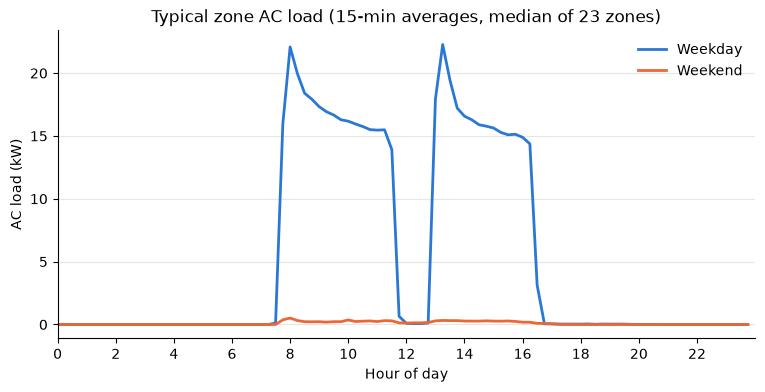

In [ ]:
# Typical zone's AC load through the day (15-minute averages):
# median across zones of each zone's average profile
profiles = {}
for key, q in zone_15min.items():
    ac = q['AC (kW)']
    day_type = np.where(ac.index.dayofweek < 5, 'Weekday', 'Weekend')
    profiles[key] = ac.groupby([day_type, ac.index.hour + ac.index.minute / 60]).mean()
profile = pd.DataFrame(profiles).median(axis=1).unstack(level=0)

fig, ax = plt.subplots(figsize=(9, 4))
for day_type, color in [('Weekday', '#2a78d6'), ('Weekend', '#eb6834')]:
    ax.plot(profile.index, profile[day_type], color=color, lw=2, label=day_type)
ax.set(xlabel='Hour of day', ylabel='AC load (kW)', xticks=range(0, 24, 2), xlim=(0, 24),
       title=f'Typical zone AC load (15-min averages, median of {len(profiles)} zones)')
ax.grid(axis='y', color='0.9')
ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False, loc='upper right')
plt.show()

## 3. Indoor conditions vs AC load

Floor 5 zone 1 is left out: its temperature sensor reads AC supply air, not room air (see `data_cleaning_summary.md`).

- **Same hour:** correlation between AC load and indoor temperature (and humidity) in the same hour.
- **Before the AC starts:** for each working day, indoor temperature (and humidity) at 07:30–07:45 (just before the AC switches on at about 07:45) vs mean AC load from 07:00 to 17:00. Days with the AC essentially off (holidays) are excluded.

In [ ]:
indoor = []
for (floor, zone), h in zone_hourly.items():
    if (floor, zone) == (5, 1):
        continue
    weekday = h[h.index.dayofweek < 5]
    ac_day = weekday[(weekday.index.hour >= 7) & (weekday.index.hour < 17)]

    # temperature just before the AC switches on (15-minute average, 07:30-07:45)
    q = zone_15min[(floor, zone)]
    temp_before = q.loc[(q.index.hour == 7) & (q.index.minute == 30), 'Temp (degC)']
    temp_before.index = temp_before.index.normalize()
    rh_before = q.loc[(q.index.hour == 7) & (q.index.minute == 30), 'RH (%)']
    rh_before.index = rh_before.index.normalize()
    daily = pd.concat([temp_before, rh_before, ac_day['AC (kW)'].resample('D').mean()],
                      axis=1, keys=['Temp at 07:30', 'RH at 07:30', 'AC 07:00-17:00'], sort=True).dropna()
    daily = daily[daily['AC 07:00-17:00'] > 0.5]

    indoor.append({
        'Floor': floor,
        'Zone': zone,
        'Temp 08:00-16:00 (degC)': weekday.loc[(weekday.index.hour >= 8) & (weekday.index.hour < 16), 'Temp (degC)'].mean(),
        'Temp overnight (degC)': h.loc[h.index.hour < 6, 'Temp (degC)'].mean(),
        'r: AC vs temp (same hour)': h['AC (kW)'].corr(h['Temp (degC)']),
        'r: daily AC vs temp at 07:30': daily['AC 07:00-17:00'].corr(daily['Temp at 07:30']),
        'r: AC vs RH (same hour)': h['AC (kW)'].corr(h['RH (%)']),
        'r: daily AC vs RH at 07:30': daily['AC 07:00-17:00'].corr(daily['RH at 07:30']),
        'Days': len(daily),
    })

indoor = pd.DataFrame(indoor).round(2)
display(indoor)
indoor.drop(columns=['Floor', 'Zone', 'Days']).median().round(2)

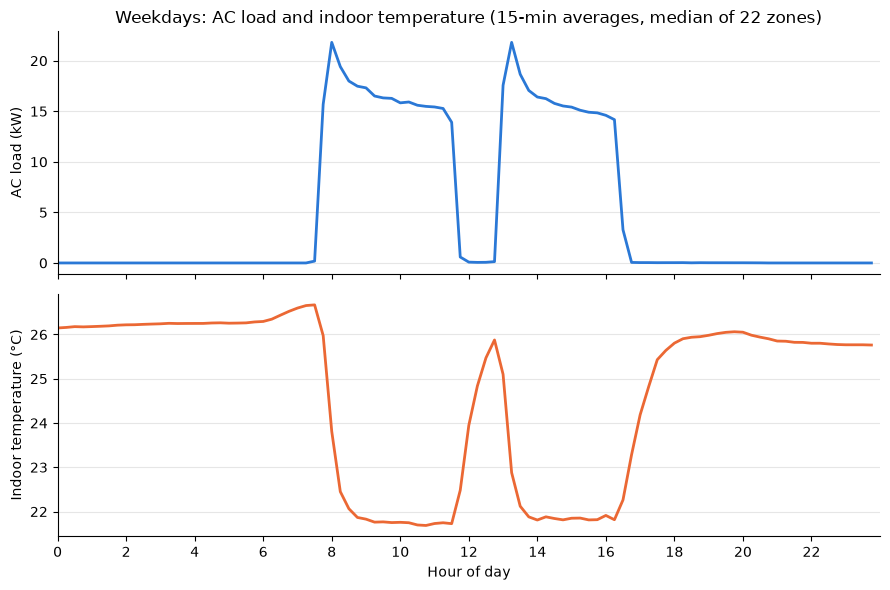

In [ ]:
# Weekday profile of AC load and indoor temperature (15-minute averages), median across zones
weekday_profiles = {}
for key, q in zone_15min.items():
    if key == (5, 1):
        continue
    weekday = q[q.index.dayofweek < 5]
    weekday_profiles[key] = weekday.groupby(weekday.index.hour + weekday.index.minute / 60).mean()
weekday_profile = pd.concat(weekday_profiles).groupby(level=-1).median()

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
ax1.plot(weekday_profile.index, weekday_profile['AC (kW)'], color='#2a78d6', lw=2)
ax1.set(ylabel='AC load (kW)',
        title=f'Weekdays: AC load and indoor temperature (15-min averages, median of {len(weekday_profiles)} zones)')
ax2.plot(weekday_profile.index, weekday_profile['Temp (degC)'], color='#eb6834', lw=2)
ax2.set(xlabel='Hour of day', ylabel='Indoor temperature (°C)', xticks=range(0, 24, 2), xlim=(0, 24))
for ax in (ax1, ax2):
    ax.grid(axis='y', color='0.9')
    ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

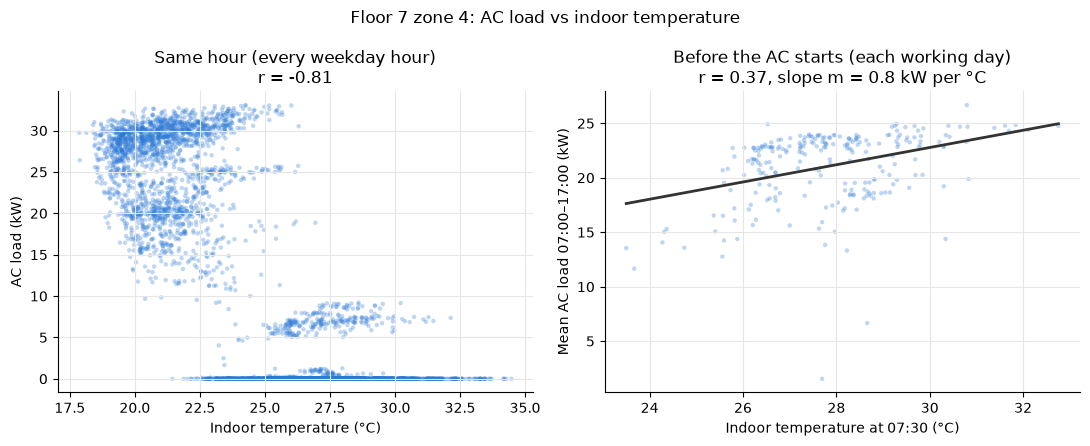

In [ ]:
# Scatter plots for one example zone (change `example` to look at another zone)
example = (7, 4)
h = zone_hourly[example]
q = zone_15min[example]
weekday = h[h.index.dayofweek < 5]

# Left: every weekday hour, AC load vs indoor temperature in the same hour
same_hour = weekday[['Temp (degC)', 'AC (kW)']].dropna()

# Right: each working day, temperature at 07:30 (before the AC starts) vs mean AC load 07:00-17:00
ac_day = weekday.loc[(weekday.index.hour >= 7) & (weekday.index.hour < 17), 'AC (kW)'].resample('D').mean()
temp_before = q.loc[(q.index.dayofweek < 5) & (q.index.hour == 7) & (q.index.minute == 30), 'Temp (degC)']
temp_before.index = temp_before.index.normalize()
daily = pd.concat([temp_before, ac_day], axis=1, keys=['Temp (degC)', 'AC (kW)'], sort=True).dropna()
daily = daily[daily['AC (kW)'] > 0.5]

# A straight line only suits the right panel; the left one has separate AC-on / AC-off clusters
panels = [(same_hour, 'Same hour (every weekday hour)',
           'Indoor temperature (°C)', 'AC load (kW)', False),
          (daily, 'Before the AC starts (each working day)',
           'Indoor temperature at 07:30 (°C)', 'Mean AC load 07:00–17:00 (kW)', True)]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (data, title, xlabel, ylabel, fit_line) in zip(axes, panels):
    x, y = data['Temp (degC)'], data['AC (kW)']
    ax.scatter(x, y, s=10, alpha=0.3, color='#2a78d6', edgecolors='none')
    title = f'{title}\nr = {x.corr(y):.2f}'
    if fit_line:
        m, c = np.polyfit(x, y, 1)                  # straight-line fit y = mx + c
        xs = np.linspace(x.min(), x.max(), 50)
        ax.plot(xs, m * xs + c, color='0.2', lw=2)
        title += f', slope m = {m:.1f} kW per °C'
    ax.set(title=title, xlabel=xlabel, ylabel=ylabel)
    ax.grid(color='0.9')
    ax.spines[['top', 'right']].set_visible(False)
fig.suptitle(f'Floor {example[0]} zone {example[1]}: AC load vs indoor temperature')
plt.tight_layout()
plt.show()

## 4. Seasonal variation in AC load

Average AC load while the AC is running (working days, 08:00–11:00 and 13:00–16:00), by month. Each zone is shown as a % of its own average so that small and large zones count equally; the line is the median across zones.

In [ ]:
# Average AC load while the AC is running (working days, 08:00-11:00 and 13:00-16:00), by month
monthly = {}
for key, h in zone_hourly.items():
    ac = h['AC (kW)']
    running = (ac.index.dayofweek < 5) & ac.index.hour.isin([8, 9, 10, 13, 14, 15])
    ac = ac[running]
    daily = ac.resample('D').mean()
    working_days = daily[daily > 0.5].index              # skip holidays (AC off all day)
    ac = ac[ac.index.normalize().isin(working_days)]
    monthly[key] = ac.groupby(ac.index.to_period('M')).mean()

monthly = pd.DataFrame(monthly)
# each zone as % of its own average, so small and large zones count equally
monthly_pct = (monthly / monthly.mean() * 100).median(axis=1).round(0)
monthly_pct

Date
2018-07     94.0
2018-08     95.0
2018-09     93.0
2018-10     96.0
2018-11     93.0
2018-12     95.0
2019-01     86.0
2019-02    101.0
2019-03    107.0
2019-04    123.0
2019-05    113.0
2019-06    111.0
2019-07    106.0
2019-08    100.0
2019-09     93.0
2019-10    103.0
2019-11     98.0
2019-12     88.0
Freq: M, dtype: float64

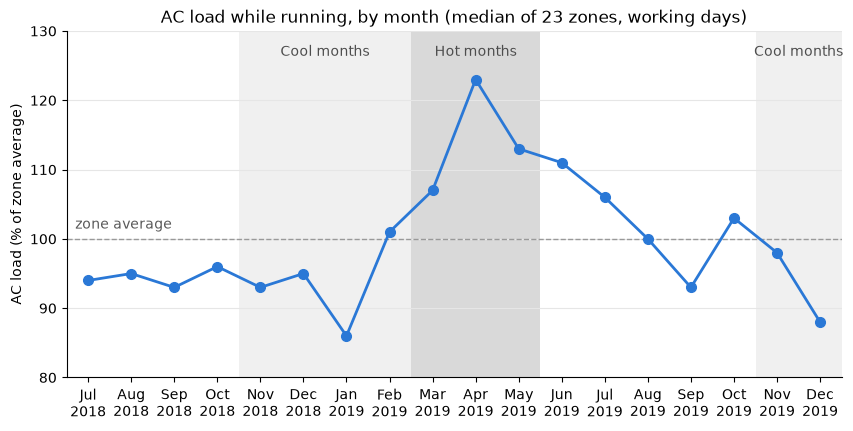

In [ ]:
fig, ax = plt.subplots(figsize=(10, 4.5))
x = range(len(monthly_pct))
months = monthly_pct.index.month

# shade the cool (Nov-Feb) and hot (Mar-May) months
shading = {'Cool months': ([11, 12, 1, 2], '0.94'), 'Hot months': ([3, 4, 5], '0.85')}
for name, (season_months, shade) in shading.items():
    idx = np.array([i for i, m in enumerate(months) if m in season_months])
    for block in np.split(idx, np.where(np.diff(idx) > 1)[0] + 1):   # consecutive months
        ax.axvspan(block[0] - 0.5, block[-1] + 0.5, color=shade, lw=0, zorder=0)
        ax.text(block.mean(), 128, name, ha='center', va='top', color='0.3')

ax.axhline(100, color='0.6', lw=1, ls='--')
ax.text(-0.3, 101, 'zone average', va='bottom', color='0.35')
ax.plot(x, monthly_pct, color='#2a78d6', lw=2, marker='o', markersize=7)
ax.set_xticks(x, monthly_pct.index.strftime('%b\n%Y'))
ax.set(ylabel='AC load (% of zone average)', ylim=(80, 130), xlim=(-0.5, len(monthly_pct) - 0.5),
       title=f'AC load while running, by month (median of {monthly.shape[1]} zones, working days)')
ax.grid(axis='y', color='0.9')
ax.spines[['top', 'right']].set_visible(False)
plt.show()

**Cool vs hot months.** Seasons follow the Thai Meteorological Department (cool: mid-Oct – mid-Feb; hot: mid-Feb – mid-May), rounded to whole months: cool = Nov–Feb, hot = Mar–May. Each zone's baseline is its average over all months (Jul 2018 – Dec 2019). Cool months come from both years; hot months come from 2019 only, since the 2018 data starts in July.

In [ ]:
# Average AC load while running in the cool (Nov-Feb) and hot (Mar-May) months
seasons = {11: 'Cool (Nov-Feb)', 12: 'Cool (Nov-Feb)', 1: 'Cool (Nov-Feb)', 2: 'Cool (Nov-Feb)',
           3: 'Hot (Mar-May)', 4: 'Hot (Mar-May)', 5: 'Hot (Mar-May)'}

season_kw, season_pct = {}, {}
for key, h in zone_hourly.items():
    ac = h['AC (kW)']
    running = (ac.index.dayofweek < 5) & ac.index.hour.isin([8, 9, 10, 13, 14, 15])
    ac = ac[running]
    daily = ac.resample('D').mean()
    working_days = daily[daily > 0.5].index              # skip holidays (AC off all day)
    ac = ac[ac.index.normalize().isin(working_days)]

    baseline = ac.mean()                                 # zone's average over all months
    by_season = ac.groupby(ac.index.month.map(seasons)).mean()
    season_kw[key] = by_season
    season_pct[key] = by_season / baseline * 100

season_summary = pd.DataFrame({
    'Typical zone kW': pd.DataFrame(season_kw).median(axis=1),
    '% of zone baseline': pd.DataFrame(season_pct).median(axis=1),
}).round(1)
season_summary

,Typical zone kW,% of zone baseline
Date,,
Cool (Nov-Feb),16.9,92.8
Hot (Mar-May),21.4,114.3


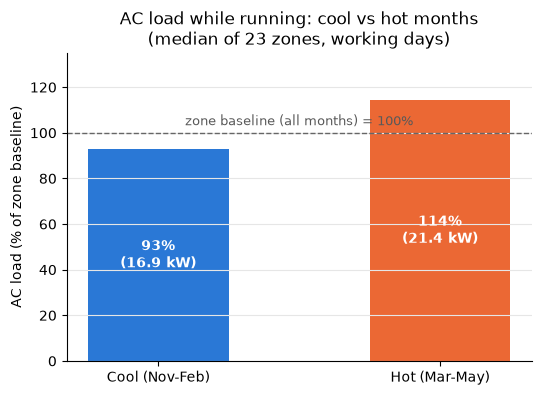

In [ ]:
fig, ax = plt.subplots(figsize=(6, 4))
colors = {'Cool (Nov-Feb)': '#2a78d6', 'Hot (Mar-May)': '#eb6834'}
names = season_summary.index
bars = ax.bar(names, season_summary['% of zone baseline'], color=[colors[n] for n in names], width=0.5)
labels = [f"{row['% of zone baseline']:.0f}%\n({row['Typical zone kW']:.1f} kW)" for _, row in season_summary.iterrows()]
ax.bar_label(bars, labels=labels, label_type='center', color='white', fontweight='bold')
ax.axhline(100, color='0.4', lw=1, ls='--')
ax.text(0.5, 102, 'zone baseline (all months) = 100%', ha='center', va='bottom', color='0.35', fontsize=9)
ax.set(ylabel='AC load (% of zone baseline)', ylim=(0, 135),
       title=f'AC load while running: cool vs hot months\n(median of {len(season_pct)} zones, working days)')
ax.grid(axis='y', color='0.9')
ax.spines[['top', 'right']].set_visible(False)
plt.show()

**Robustness check: public holidays.** Days with the AC off all day (e.g. public holidays) are already excluded, but quieter days around holidays are still included. To check whether they explain the difference, the comparison is repeated without the months that have the most public holidays: December and January (New Year) from the cool months, and April (Songkran) from the hot months.

In [ ]:
groups = {'Cool (Nov-Feb)': [11, 12, 1, 2],
          'Cool without Dec, Jan (Nov, Feb)': [11, 2],
          'Hot (Mar-May)': [3, 4, 5],
          'Hot without Apr (Mar, May)': [3, 5]}

holiday_check = {name: [] for name in groups}
for key, h in zone_hourly.items():
    ac = h['AC (kW)']
    running = (ac.index.dayofweek < 5) & ac.index.hour.isin([8, 9, 10, 13, 14, 15])
    ac = ac[running]
    daily = ac.resample('D').mean()
    working_days = daily[daily > 0.5].index              # skip holidays (AC off all day)
    ac = ac[ac.index.normalize().isin(working_days)]
    for name, months in groups.items():
        holiday_check[name].append(ac[ac.index.month.isin(months)].mean())

# typical zone (median across zones), kW while running
pd.DataFrame(holiday_check).median().round(1).rename('Typical zone kW')

Cool (Nov-Feb)                      16.9
Cool without Dec, Jan (Nov, Feb)    17.3
Hot (Mar-May)                       21.4
Hot without Apr (Mar, May)          20.3
Name: Typical zone kW, dtype: float64

## 5. Working hours vs after hours

How the working hours are derived from the AC load. For each zone, take the typical weekday (average of every Monday–Friday, one value per 15 minutes), then:

1. **Off level:** median load from 00:00 to 05:00. **On level:** median load from 09:00–11:00 and 13:00–15:00.
2. **Threshold:** a slot counts as "on" once load is a quarter of the way from the off level to the on level. Using a share of each zone's own range, not a fixed kW, lets small and large zones be judged the same way.
3. **Start** = first "on" slot before noon. **End** = last "on" slot after noon, plus the 15 minutes that slot covers.
4. **Lunch break** = slots between 11:00 and 14:00 that drop back below the threshold.

Everything outside the start–end window on weekdays, and all of Saturday and Sunday, is after hours.

In [ ]:
def hhmm(t):
    return f'{int(t):02d}:{int(round((t % 1) * 60)):02d}'

hours = []
for (floor, zone), q in zone_15min.items():
    ac = q['AC (kW)']
    ac = ac[ac.index.dayofweek < 5]
    slot = ac.index.hour + ac.index.minute / 60
    p = ac.groupby(slot).mean()                              # typical weekday, one value per 15 minutes

    # Step 1: how high is "off" and how high is "on"?
    baseline = p[p.index < 5].median()                       # 00:00-05:00, AC certainly not wanted
    plateau = p[((p.index >= 9) & (p.index < 11)) | ((p.index >= 13) & (p.index < 15))].median()
    # Step 2: call a slot "on" once it is a quarter of the way from baseline to plateau
    threshold = baseline + 0.25 * (plateau - baseline)
    on = p > threshold
    # Step 3: first "on" slot before noon = start, last "on" slot after noon = end
    start = on[on & (p.index < 12)].index.min()
    end = on[on & (p.index >= 12)].index.max() + 0.25        # a slot covers the 15 minutes after its label
    # Step 4: slots between 11:00 and 14:00 that fall back to "off" = lunch break
    lunch = on[(p.index >= 11) & (p.index < 14) & ~on].index
    hours.append({'Floor': floor, 'Zone': zone,
                  'Off kW': baseline, 'On kW': plateau, 'Threshold kW': threshold,
                  'Start': hhmm(start), 'End': hhmm(end),
                  'Lunch off': f'{hhmm(lunch.min())}-{hhmm(lunch.max() + 0.25)}' if len(lunch) else '-'})

working_hours = pd.DataFrame(hours).round(2)
display(working_hours)
working_hours[['Start', 'End', 'Lunch off']].apply(lambda s: s.value_counts().head(3))

,Floor,Zone,Off kW,On kW,Threshold kW,Start,End,Lunch off
0,2,1,0.04,27.18,6.83,07:45,18:15,-
1,2,2,6.01,25.43,10.86,07:45,17:15,-
2,2,4,0.00,8.36,2.09,07:45,17:00,-
3,3,1,0.03,21.08,5.29,07:45,16:30,11:45-13:00
4,3,2,0.00,16.48,4.12,07:45,16:30,11:45-13:00
5,3,4,0.00,16.83,4.21,07:45,16:30,11:45-13:00
6,3,5,0.00,7.81,1.95,07:45,16:30,11:45-13:00
7,4,1,0.00,20.16,5.04,07:45,16:30,11:45-13:00
8,4,2,0.00,14.73,3.68,07:45,16:30,11:45-13:00
9,4,4,0.00,19.01,4.75,07:45,16:30,11:45-13:00


,Start,End,Lunch off
-,NaN,NaN,3.0
07:45,23.0,NaN,NaN
11:45-13:00,NaN,NaN,20.0
16:30,NaN,16.0,NaN
17:00,NaN,5.0,NaN
18:15,NaN,1.0,NaN


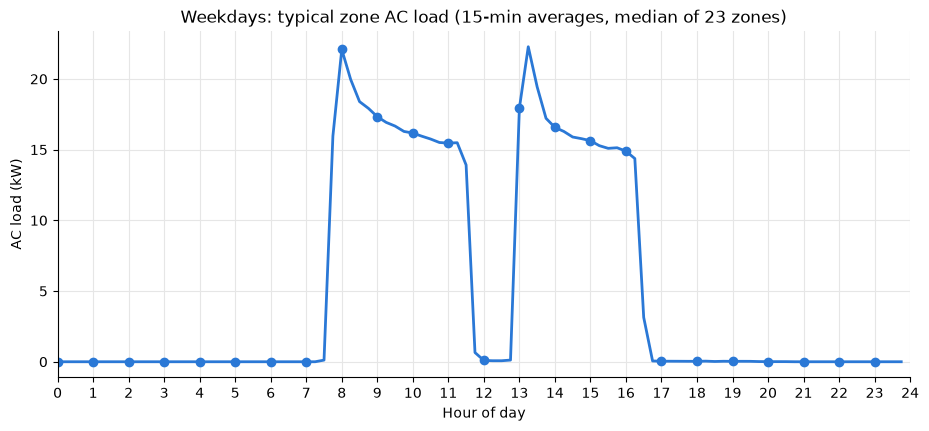

In [ ]:
# Weekday AC load with a marker on every hour (15-minute averages, median across zones)
ac_profiles = {}
for key, q in zone_15min.items():
    weekday = q[q.index.dayofweek < 5]['AC (kW)']
    ac_profiles[key] = weekday.groupby(weekday.index.hour + weekday.index.minute / 60).mean()
ac_profile = pd.DataFrame(ac_profiles).median(axis=1)

on_the_hour = ac_profile[ac_profile.index % 1 == 0]          # one marker per full hour

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(ac_profile.index, ac_profile, color='#2a78d6', lw=2)
ax.plot(on_the_hour.index, on_the_hour, 'o', color='#2a78d6', markersize=6)
ax.set(xlabel='Hour of day', ylabel='AC load (kW)', xticks=range(0, 25), xlim=(0, 24),
       title=f'Weekdays: typical zone AC load (15-min averages, median of {len(ac_profiles)} zones)')
ax.grid(color='0.9')
ax.spines[['top', 'right']].set_visible(False)
plt.show()

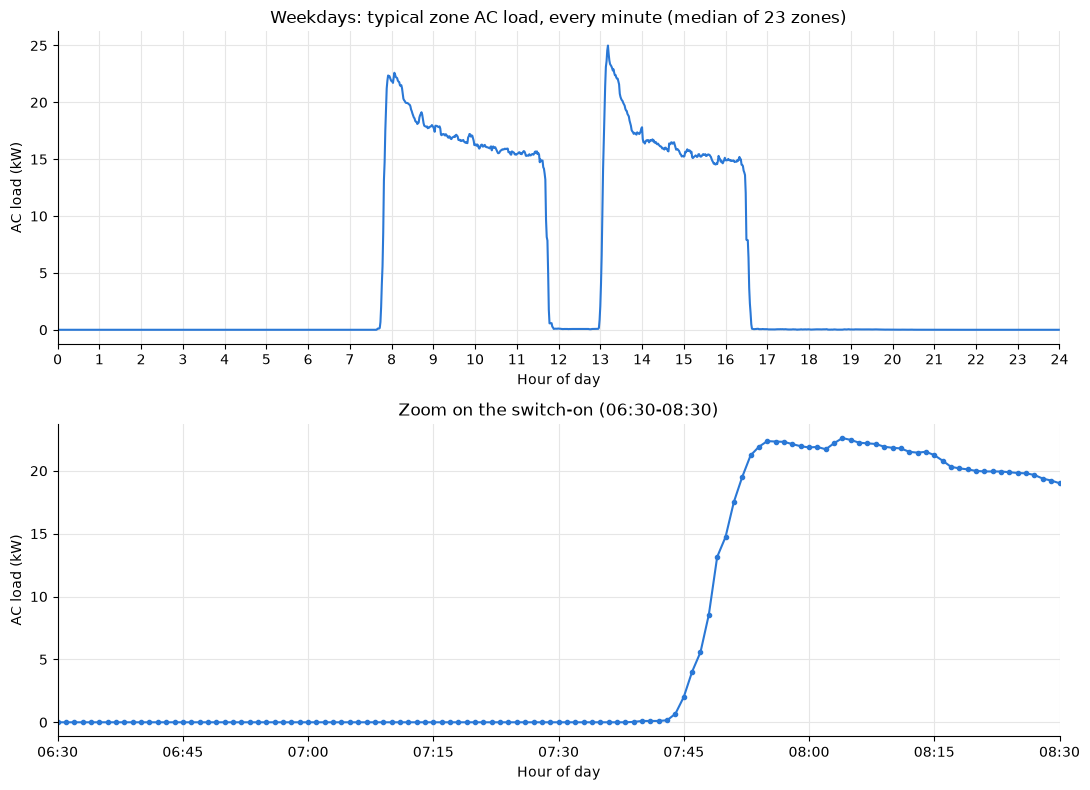

In [ ]:
# Weekday AC load, minute by minute (no resampling): average of every weekday at each minute of the day,
# then the median across zones
minute_profiles = {}
for floor, g in all_data[all_data['Floor'] != 1].set_index('Date').groupby('Floor'):
    for zone in [1, 2, 4, 5]:
        ac = [c for c in ac_cols
              if c.startswith(f'z{zone}_AC') and g[c].notna().any() and g[c].std() > 0]
        if not ac:
            continue
        load = g[ac].sum(axis=1, min_count=len(ac))         # NaN if any unit is missing
        load = load[load.index.dayofweek < 5]
        minute_profiles[(floor, zone)] = load.groupby(load.index.hour * 60 + load.index.minute).mean()
minute_profile = pd.DataFrame(minute_profiles).median(axis=1)
hours = minute_profile.index / 60                           # minute of day -> hour of day

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 8))
ax1.plot(hours, minute_profile, color='#2a78d6', lw=1.5)
ax1.set(xlabel='Hour of day', ylabel='AC load (kW)', xticks=range(0, 25), xlim=(0, 24),
        title=f'Weekdays: typical zone AC load, every minute (median of {len(minute_profiles)} zones)')

# zoom on the switch-on, 06:30-08:30, one marker per minute
zoom = minute_profile.loc[6 * 60 + 30: 8 * 60 + 30]
ax2.plot(zoom.index / 60, zoom, color='#2a78d6', lw=1.5, marker='o', markersize=3)
ax2.set(xlabel='Hour of day', ylabel='AC load (kW)', xlim=(6.5, 8.5),
        xticks=np.arange(6.5, 8.51, 0.25), xticklabels=['06:30', '06:45', '07:00', '07:15', '07:30', '07:45', '08:00', '08:15', '08:30'],
        title='Zoom on the switch-on (06:30-08:30)')
for ax in (ax1, ax2):
    ax.grid(color='0.9')
    ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

## 6. AC load by zone

Average AC load of every zone in four situations: a weekday during working hours (08:00-17:00), a weekday after hours (the rest of the day), a weekend (all day) and a public holiday (all day). Weekdays exclude holidays (the `holiday?` column).

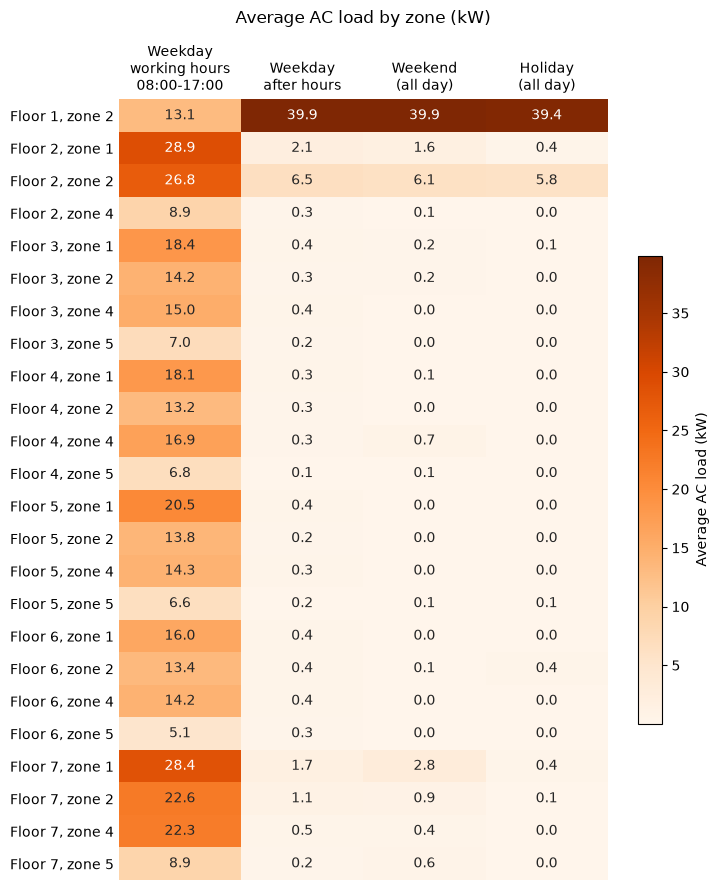

In [ ]:
# Average AC load of each zone in four situations (kW).
# Leaves out the 23 Jan - 12 Feb 2019 meter outage, when several floors recorded nothing.
outage = (all_data['Date'] >= '2019-01-23') & (all_data['Date'] < '2019-02-13')

rows = {}
for floor, g in all_data[~outage].groupby('Floor'):
    for zone in [1, 2, 4, 5]:
        ac = [c for c in ac_cols
              if c.startswith(f'z{zone}_AC') and g[c].notna().any() and g[c].std() > 0]
        if not ac:
            continue
        load = g[ac].sum(axis=1, min_count=len(ac))
        hour, dow, holiday = g['Date'].dt.hour, g['Date'].dt.dayofweek, g['holiday?'] == 'Yes'
        weekday = (dow < 5) & ~holiday
        working = (hour >= 8) & (hour < 17)
        rows[f'Floor {floor}, zone {zone}'] = {
            'Weekday\nworking hours\n08:00-17:00': load[weekday & working].mean(),
            'Weekday\nafter hours': load[weekday & ~working].mean(),
            'Weekend\n(all day)': load[dow >= 5].mean(),
            'Holiday\n(all day)': load[holiday].mean(),
        }
zone_load = pd.DataFrame(rows).T

fig, ax = plt.subplots(figsize=(7.5, 9))
im = ax.imshow(zone_load, cmap='Oranges', aspect='auto')
ax.set_xticks(range(zone_load.shape[1]), zone_load.columns)
ax.set_yticks(range(zone_load.shape[0]), zone_load.index)
ax.xaxis.tick_top()
ax.tick_params(length=0)
for i in range(zone_load.shape[0]):
    for j in range(zone_load.shape[1]):
        v = zone_load.iloc[i, j]
        ax.text(j, i, f'{v:.1f}', ha='center', va='center',
                color='white' if v > zone_load.values.max() * 0.6 else '0.15')
ax.spines[:].set_visible(False)
fig.colorbar(im, ax=ax, label='Average AC load (kW)', shrink=0.6)
ax.set_title('Average AC load by zone (kW)', pad=55)
plt.tight_layout()
plt.show()

**Note.** The averages are taken straight from the minute-by-minute readings, with no grouping into hourly or 15-minute blocks. Each zone's load is the sum of its working AC units in that minute; minutes where any of its units did not record are skipped.

Two AC meters are excluded because they read exactly 0 kW for the whole record, so they add nothing: `z2_AC11` (Floor 2, zone 2) and `z1_AC1` (Floor 7, zone 1). Floor 2 zone 2 therefore uses 13 units and Floor 7 zone 1 uses 3. The 23 Jan - 12 Feb 2019 meter outage is also left out.

## 7. AC data completeness by zone

For each zone and month: the % of minutes in which every working AC unit of the zone recorded a reading. A zone's reading is missing for a minute if any one of its units did not record. Grey means no data at all for that month (Floor 6 after 22 Oct 2019). The two constant meters (`z2_AC11`, `z1_AC1` on Floor 7) are not counted.

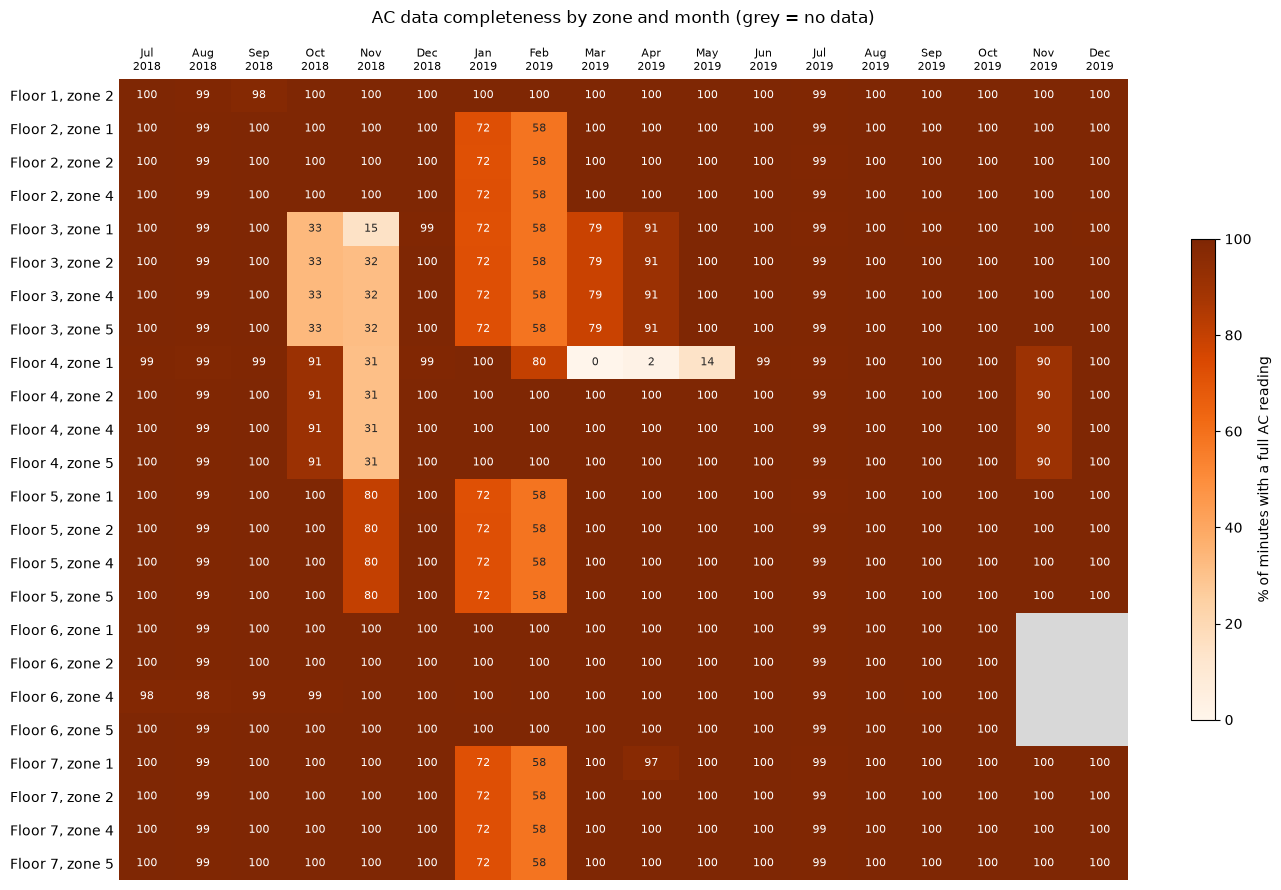

In [ ]:
# % of minutes in each month when every working AC unit of the zone recorded a reading
completeness = {}
for floor, g in all_data.groupby('Floor'):
    month = g['Date'].dt.to_period('M')
    for zone in [1, 2, 4, 5]:
        ac = [c for c in ac_cols
              if c.startswith(f'z{zone}_AC') and g[c].notna().any() and g[c].std() > 0]
        if not ac:
            continue
        completeness[f'Floor {floor}, zone {zone}'] = g[ac].notna().all(axis=1).groupby(month).mean() * 100
completeness = pd.DataFrame(completeness).T           # rows = zones, columns = months
completeness.columns = completeness.columns.strftime('%b\n%Y')

cmap = plt.get_cmap('Oranges').copy()
cmap.set_bad('0.85')                                   # grey = no data at all for that month

fig, ax = plt.subplots(figsize=(14, 9))
im = ax.imshow(completeness.astype(float), cmap=cmap, vmin=0, vmax=100, aspect='auto')
ax.set_xticks(range(completeness.shape[1]), completeness.columns, fontsize=8)
ax.set_yticks(range(completeness.shape[0]), completeness.index)
ax.xaxis.tick_top()
ax.tick_params(length=0)
for i in range(completeness.shape[0]):
    for j in range(completeness.shape[1]):
        v = completeness.iloc[i, j]
        if not np.isnan(v):
            ax.text(j, i, f'{v:.0f}', ha='center', va='center', fontsize=8,
                    color='white' if v > 60 else '0.15')
ax.spines[:].set_visible(False)
fig.colorbar(im, ax=ax, label='% of minutes with a full AC reading', shrink=0.6)
ax.set_title('AC data completeness by zone and month (grey = no data)', pad=40)
plt.tight_layout()
plt.show()

### Completeness of each AC meter

The same idea for every individual AC meter: the % of minutes in each month when the meter recorded a reading. Rows are grouped by floor, then zone, then AC unit. Grey means no data at all for that month (Floor 6 after 22 Oct 2019). The two constant meters (`z2_AC11` on Floor 2, `z1_AC1` on Floor 7) are not shown.

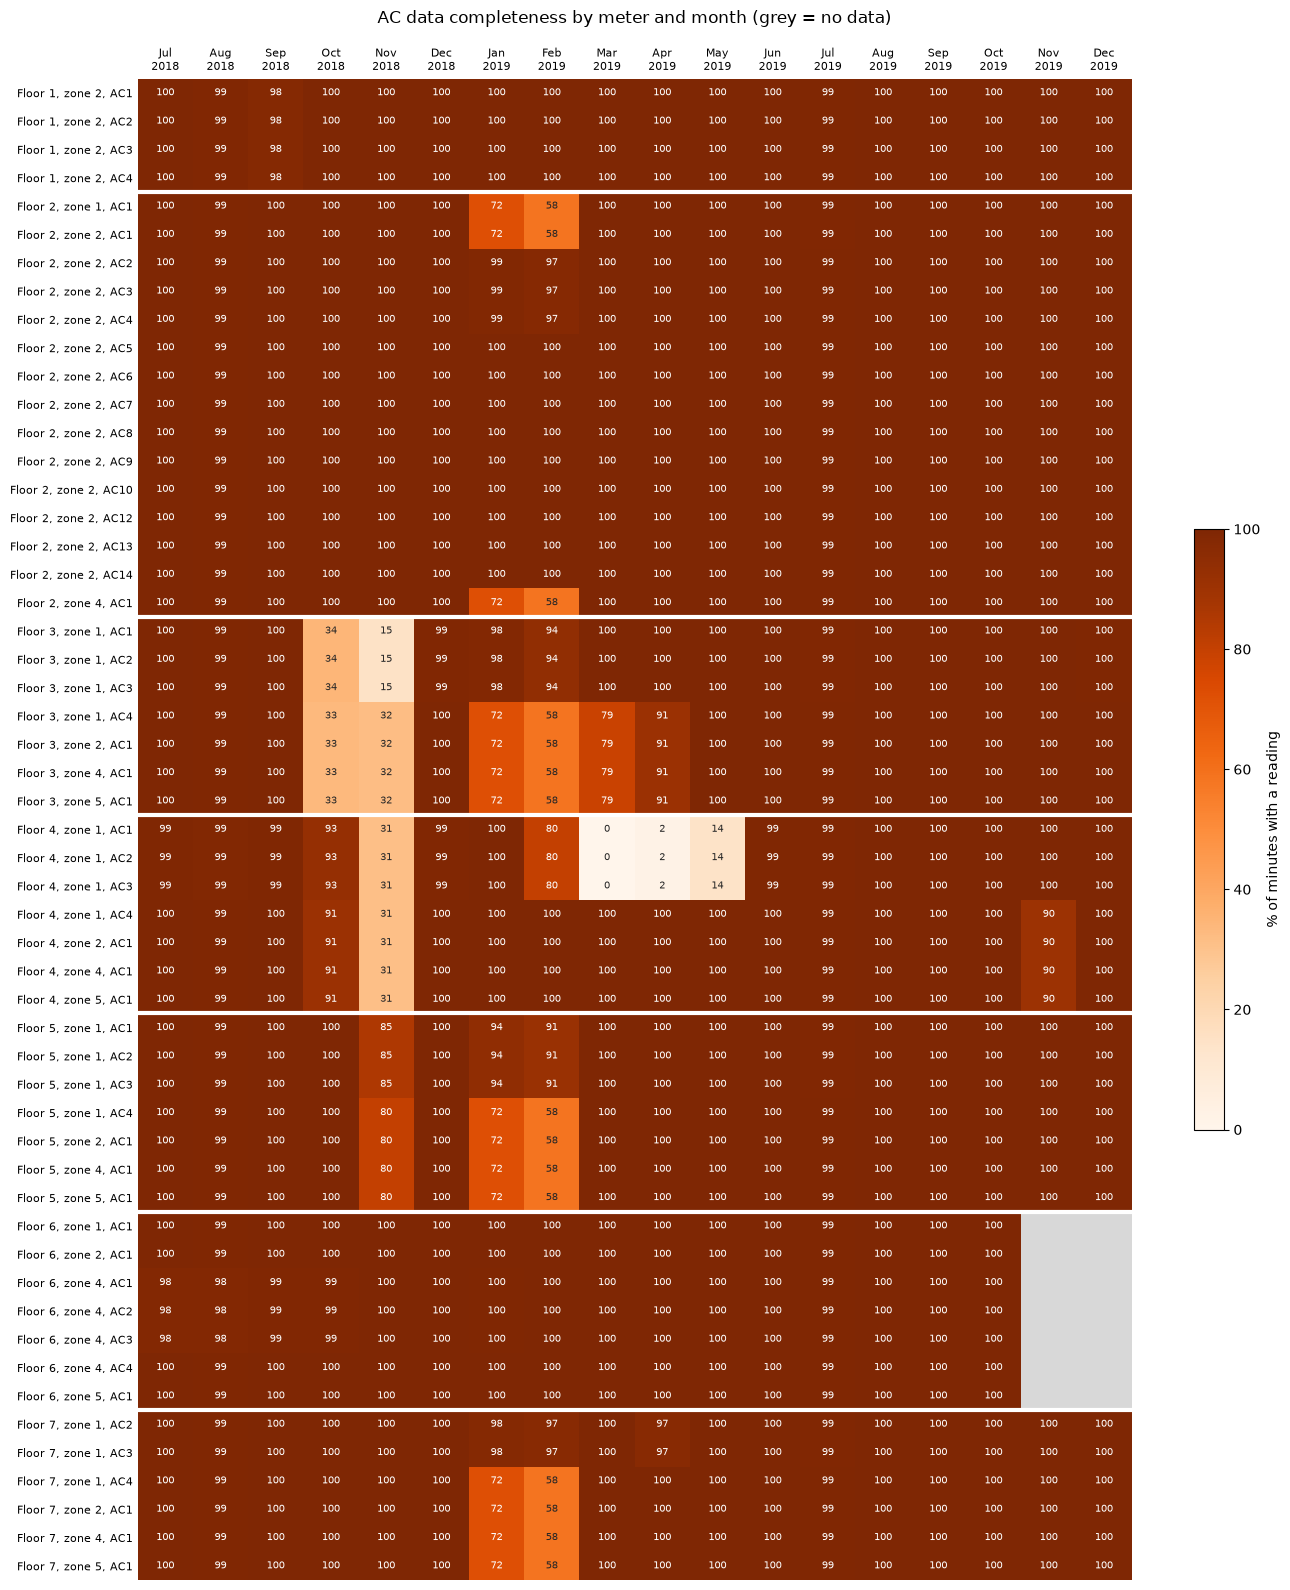

In [ ]:
# % of minutes in each month when each individual AC meter recorded a reading
meter_completeness = {}
for floor, g in all_data.groupby('Floor'):
    month = g['Date'].dt.to_period('M')
    working = [c for c in ac_cols if g[c].notna().any() and g[c].std() > 0]   # meters that exist here and change
    # order by zone, then by AC number (z2_AC10 comes after z2_AC9)
    working.sort(key=lambda c: (int(c.split('_AC')[0][1:]), int(c.split('_AC')[1].replace('(kW)', ''))))
    for c in working:
        zone, unit = c.split('_AC')[0][1:], c.split('_AC')[1].replace('(kW)', '')
        meter_completeness[f'Floor {floor}, zone {zone}, AC{unit}'] = g[c].notna().groupby(month).mean() * 100
meter_completeness = pd.DataFrame(meter_completeness).T
meter_completeness.columns = meter_completeness.columns.strftime('%b\n%Y')

cmap = plt.get_cmap('Oranges').copy()
cmap.set_bad('0.85')                                       # grey = no data at all for that month

fig, ax = plt.subplots(figsize=(14, 16))
im = ax.imshow(meter_completeness.astype(float), cmap=cmap, vmin=0, vmax=100, aspect='auto')
ax.set_xticks(range(meter_completeness.shape[1]), meter_completeness.columns, fontsize=8)
ax.set_yticks(range(meter_completeness.shape[0]), meter_completeness.index, fontsize=8)
ax.xaxis.tick_top()
ax.tick_params(length=0)
for i in range(meter_completeness.shape[0]):
    for j in range(meter_completeness.shape[1]):
        v = meter_completeness.iloc[i, j]
        if not np.isnan(v):
            ax.text(j, i, f'{v:.0f}', ha='center', va='center', fontsize=7,
                    color='white' if v > 60 else '0.15')
floors = meter_completeness.index.str.extract(r'Floor (\d)')[0].values
for i in range(1, len(floors)):                            # a line between floors
    if floors[i] != floors[i - 1]:
        ax.axhline(i - 0.5, color='white', lw=3)
ax.spines[:].set_visible(False)
fig.colorbar(im, ax=ax, label='% of minutes with a reading', shrink=0.4)
ax.set_title('AC data completeness by meter and month (grey = no data)', pad=40)
plt.tight_layout()
plt.show()

## 8. Evidence: was the office open on Labour Day 2019?

Labour Day (1 May) is a holiday for banks and the private sector, but not for the government. This compares the AC load on Wednesday 1 May 2019 with a typical working weekday and with a day the office was closed (Songkran, 15 April 2019). If the office had been closed, the Labour Day line would sit on the grey dashed line.

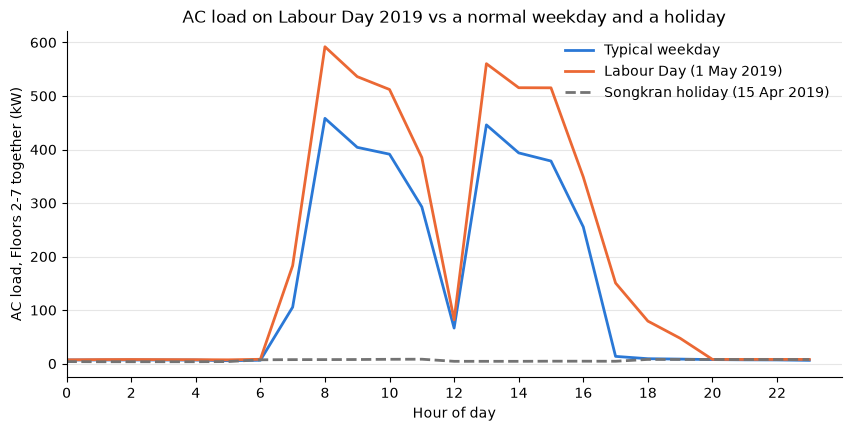

,Normal weekday (kW),Labour Day (kW),Labour Day as % of normal,Songkran 15 Apr (kW)
Floor,,,,
2,64.2,78.8,122.8,5.9
3,52.6,69.7,132.4,0.0
4,54.4,68.0,125.1,0.0
5,54.3,71.1,130.9,0.0
6,47.1,63.1,134.0,0.0
7,83.0,99.0,119.3,0.1


In [ ]:
# Evidence: was the office working on Labour Day (Wed 1 May 2019)?
# AC load of the office floors (2-7), by hour of day, for three kinds of day.
office = all_data[all_data['Floor'] >= 2].copy()
office['AC total'] = office[ac_cols].sum(axis=1, min_count=1)
building = office.groupby('Date')['AC total'].sum()                 # all office floors together, each minute
hourly = building.groupby([building.index.normalize(), building.index.hour]).mean().unstack()   # rows = days, columns = hours

days = hourly.index
is_weekday = days.dayofweek < 5
is_holiday = days.isin(all_data.loc[all_data['holiday?'] == 'Yes', 'Date'].dt.normalize().unique())
outage = (days >= '2019-01-23') & (days < '2019-02-13')

typical = hourly[is_weekday & ~is_holiday & ~outage].median()       # a normal working weekday
labour_day = hourly.loc['2019-05-01']
songkran = hourly.loc['2019-04-15']                                  # a day the office was closed

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(typical.index, typical, color='#2a78d6', lw=2, label='Typical weekday')
ax.plot(labour_day.index, labour_day, color='#eb6834', lw=2, label='Labour Day (1 May 2019)')
ax.plot(songkran.index, songkran, color='0.45', lw=2, ls='--', label='Songkran holiday (15 Apr 2019)')
ax.set(xlabel='Hour of day', ylabel='AC load, Floors 2-7 together (kW)', xticks=range(0, 24, 2), xlim=(0, 24),
       title='AC load on Labour Day 2019 vs a normal weekday and a holiday')
ax.grid(axis='y', color='0.9')
ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False, loc='upper right')
plt.show()

# the same comparison as numbers: average AC load 08:00-17:00 on each floor
floor_day = office[(office['Date'].dt.hour >= 8) & (office['Date'].dt.hour < 17)]
floor_day = floor_day.groupby(['Floor', floor_day['Date'].dt.normalize()])['AC total'].mean().unstack(0)
normal = floor_day[(floor_day.index.dayofweek < 5) & ~floor_day.index.isin(days[is_holiday]) &
                   ~((floor_day.index >= '2019-01-23') & (floor_day.index < '2019-02-13'))].median()
pd.DataFrame({'Normal weekday (kW)': normal,
              'Labour Day (kW)': floor_day.loc['2019-05-01'],
              'Labour Day as % of normal': floor_day.loc['2019-05-01'] / normal * 100,
              'Songkran 15 Apr (kW)': floor_day.loc['2019-04-15']}).round(1)

## 9. AC load vs outdoor weather

Scatterplots for one AC unit, Floor 2 zone 2 AC1 (the largest of the 13 units in that zone; `z2_AC11` is excluded). Weather is daily, so each point is one working weekday: the unit's average load from 08:00 to 17:00 against that day's weather. Weekends and holidays are left out, and so are days with fewer than 90% of the 540 minutes recorded.

Top row: rainfall. Bottom row: average outdoor temperature. The left plot in each row is the plain scatterplot; the right plot is the same points with a straight-line trendline (slope and correlation r in the title).

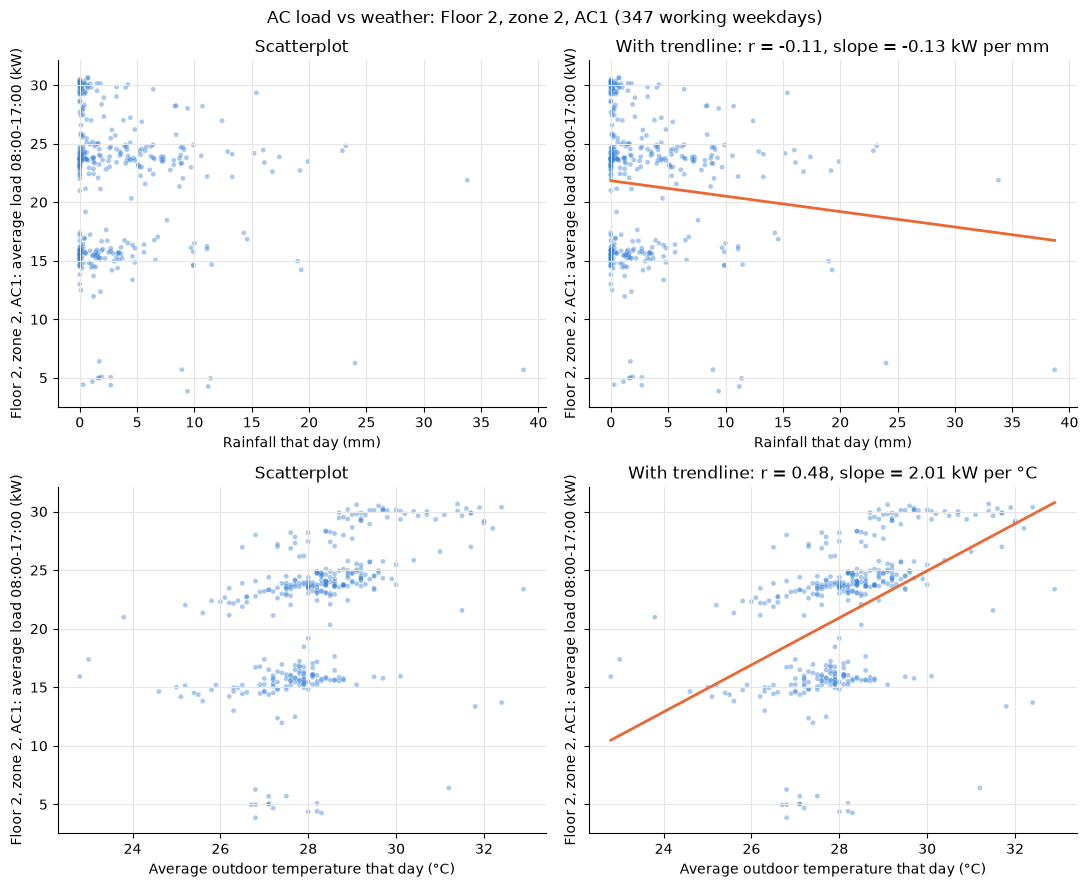

In [ ]:
# One AC unit: Floor 2, zone 2, AC1 (the largest of the 13 units in that zone).
# One point per working weekday: the unit's average load from 08:00 to 17:00 against that day's weather.
unit = 'z2_AC1(kW)'
g = all_data[(all_data['Floor'] == 2) & (all_data['Date'].dt.hour >= 8) & (all_data['Date'].dt.hour < 17)
             & (all_data['Date'].dt.dayofweek < 5) & (all_data['holiday?'] == 'No')].copy()
g['Day'] = g['Date'].dt.normalize()

daily = g.groupby('Day').agg(load=(unit, 'mean'), minutes=(unit, 'count'),
                             rain=('rainfall (mm)', 'first'), temp=('outdoor temp (degC)', 'first'))
daily = daily[daily['minutes'] >= 0.9 * 540]            # keep days with at least 90% of the 540 minutes recorded

fig, axes = plt.subplots(2, 2, figsize=(11, 9), sharey=True)
rows = [('rain', 'Rainfall that day (mm)', 'mm'),
        ('temp', 'Average outdoor temperature that day (°C)', '°C')]
for (col, xlabel, unit_text), (ax_plain, ax_line) in zip(rows, axes):
    x, y = daily[col], daily['load']
    for ax in (ax_plain, ax_line):
        ax.scatter(x, y, s=12, alpha=0.4, color='#2a78d6', edgecolors='none')
        ax.set(xlabel=xlabel, ylabel='Floor 2, zone 2, AC1: average load 08:00-17:00 (kW)')
        ax.grid(color='0.9')
        ax.spines[['top', 'right']].set_visible(False)
    ax_plain.set_title('Scatterplot')
    m, c = np.polyfit(x, y, 1)                       # straight-line fit: load = m * weather + c
    xs = np.linspace(x.min(), x.max(), 50)
    ax_line.plot(xs, m * xs + c, color='#eb6834', lw=2)
    ax_line.set_title(f'With trendline: r = {x.corr(y):.2f}, slope = {m:.2f} kW per {unit_text}')
fig.suptitle(f'AC load vs weather: Floor 2, zone 2, AC1 ({len(daily)} working weekdays)')
plt.tight_layout()
plt.show()

## 10. AC load vs outdoor weather, by hour

The same question as section 9, but with hourly weather instead of daily. Each point is one hour of a working weekday (08:00-17:00): the average load of Floor 2, zone 2, AC1 in that hour against the temperature or rainfall in the same hour. Weekends and holidays are left out, and so are hours with fewer than 90% of the 60 minutes recorded. In each figure the left plot is the plain scatterplot and the right plot has a straight-line trendline.

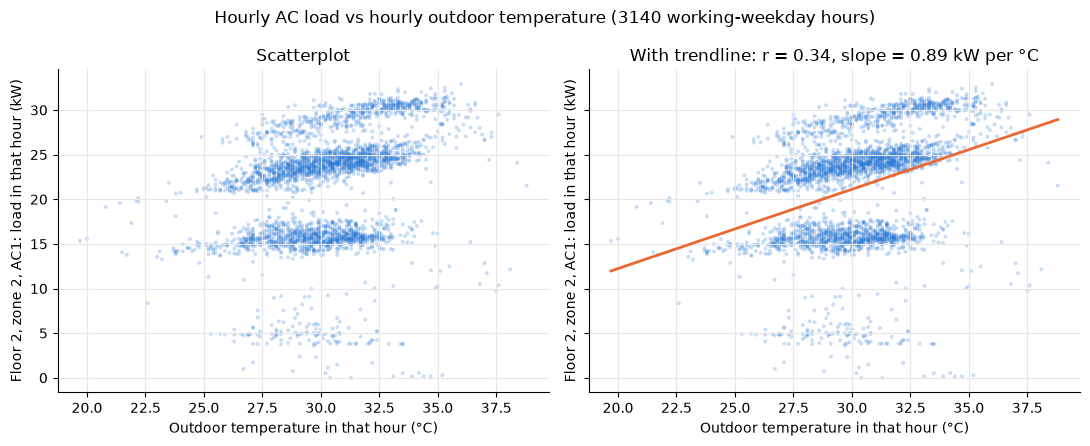

In [ ]:
# Hourly AC load of one unit (Floor 2, zone 2, AC1) on working weekdays, 08:00-17:00, with that hour's weather.
unit = 'z2_AC1(kW)'
g = all_data[(all_data['Floor'] == 2) & (all_data['Date'].dt.hour >= 8) & (all_data['Date'].dt.hour < 17)
             & (all_data['Date'].dt.dayofweek < 5) & (all_data['holiday?'] == 'No')].copy()
g['Hour'] = g['Date'].dt.floor('h')

hourly_floor2 = g.groupby('Hour').agg(load=(unit, 'mean'), minutes=(unit, 'count'),
                                      rain=('hourly rainfall (mm)', 'first'),
                                      temp=('hourly outdoor temp (degC)', 'first'))
hourly_floor2 = hourly_floor2[hourly_floor2['minutes'] >= 0.9 * 60]    # keep hours with at least 90% of the 60 minutes recorded

# AC load vs hourly outdoor temperature: left = scatterplot, right = the same points with a trendline
x, y = hourly_floor2['temp'], hourly_floor2['load']
fig, (ax_plain, ax_line) = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
for ax in (ax_plain, ax_line):
    ax.scatter(x, y, s=8, alpha=0.25, color='#2a78d6', edgecolors='none')
    ax.set(xlabel='Outdoor temperature in that hour (°C)', ylabel='Floor 2, zone 2, AC1: load in that hour (kW)')
    ax.grid(color='0.9')
    ax.spines[['top', 'right']].set_visible(False)
ax_plain.set_title('Scatterplot')
m, c = np.polyfit(x, y, 1)                       # straight-line fit: load = m * temperature + c
xs = np.linspace(x.min(), x.max(), 50)
ax_line.plot(xs, m * xs + c, color='#eb6834', lw=2)
ax_line.set_title(f'With trendline: r = {x.corr(y):.2f}, slope = {m:.2f} kW per °C')
fig.suptitle(f'Hourly AC load vs hourly outdoor temperature ({len(hourly_floor2)} working-weekday hours)')
plt.tight_layout()
plt.show()

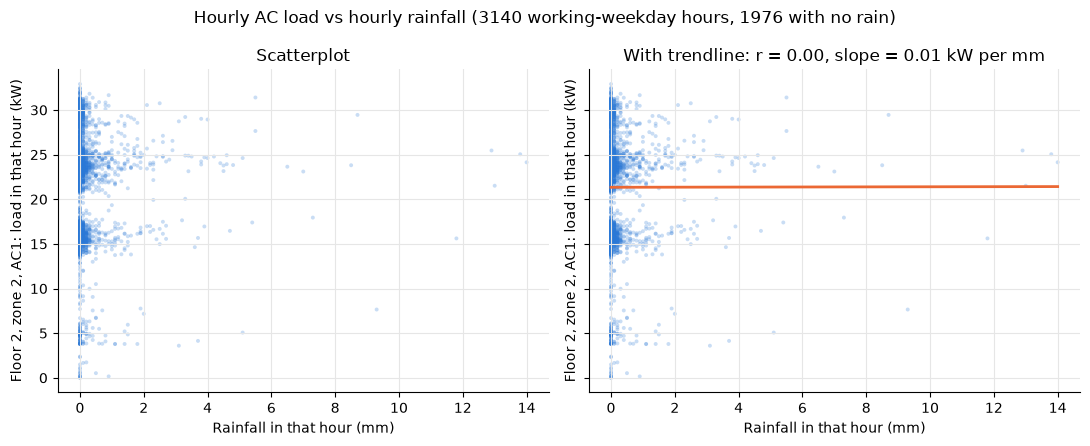

In [ ]:
# AC load vs hourly rainfall (uses hourly_floor2 from the cell above): left = scatterplot, right = with a trendline
x, y = hourly_floor2['rain'], hourly_floor2['load']
fig, (ax_plain, ax_line) = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
for ax in (ax_plain, ax_line):
    ax.scatter(x, y, s=8, alpha=0.25, color='#2a78d6', edgecolors='none')
    ax.set(xlabel='Rainfall in that hour (mm)', ylabel='Floor 2, zone 2, AC1: load in that hour (kW)')
    ax.grid(color='0.9')
    ax.spines[['top', 'right']].set_visible(False)
ax_plain.set_title('Scatterplot')
m, c = np.polyfit(x, y, 1)                       # straight-line fit: load = m * rainfall + c
xs = np.linspace(x.min(), x.max(), 50)
ax_line.plot(xs, m * xs + c, color='#eb6834', lw=2)
ax_line.set_title(f'With trendline: r = {x.corr(y):.2f}, slope = {m:.2f} kW per mm')
fig.suptitle(f'Hourly AC load vs hourly rainfall ({len(hourly_floor2)} working-weekday hours, {int((x == 0).sum())} with no rain)')
plt.tight_layout()
plt.show()

## 11. Charts for the slides

The two charts on the Preliminary results slides. They use the whole of Floor 2, zone 2 (the sum of its 13 working AC units, `z2_AC11` is excluded), working weekdays from 08:00 to 17:00, hourly, in the modelling window (March to December 2019). Hours with fewer than 90% of the 60 minutes recorded are left out. The first cell prepares the data and prints the numbers quoted on the slides; the next two draw the charts and save them as `slide_rainfall.png` and `slide_temperature.png`.

In [ ]:
# Charts for the slides: Floor 2, zone 2 AC load against hourly weather.
# Zone AC load = the sum of the zone's working AC units (z2_AC11 is excluded because it reads 0 throughout).
zone_units = [c for c in ac_cols if c.startswith('z2_AC')
              and all_data.loc[all_data['Floor'] == 2, c].notna().any()
              and all_data.loc[all_data['Floor'] == 2, c].std() > 0]
print(len(zone_units), 'working AC units in Floor 2, zone 2')

# modelling window (March-December 2019), working weekdays, 08:00-17:00
g = all_data[(all_data['Floor'] == 2) & (all_data['Date'] >= '2019-03-01')
             & (all_data['Date'].dt.hour >= 8) & (all_data['Date'].dt.hour < 17)
             & (all_data['Date'].dt.dayofweek < 5) & (all_data['holiday?'] == 'No')].copy()
g['AC zone'] = g[zone_units].sum(axis=1, min_count=len(zone_units))     # NaN if any unit is missing
g['Hour'] = g['Date'].dt.floor('h')

slide_hours = g.groupby('Hour').agg(load=('AC zone', 'mean'), minutes=('AC zone', 'count'),
                                    rain=('hourly rainfall (mm)', 'first'),
                                    temp=('hourly outdoor temp (degC)', 'first'))
slide_hours = slide_hours[slide_hours['minutes'] >= 0.9 * 60]            # hours with at least 90% of the 60 minutes recorded

# the numbers quoted on the slides
month = slide_hours.index.to_period('M')
within = lambda s: s - s.groupby(month).transform('mean')                # remove each month's average level
print(len(slide_hours), 'hours')
print('temperature: r =', round(slide_hours['temp'].corr(slide_hours['load']), 3),
      '| slope =', round(np.polyfit(slide_hours['temp'], slide_hours['load'], 1)[0], 3), 'kW per degC',
      '| r within the same month =', round(within(slide_hours['temp']).corr(within(slide_hours['load'])), 3))
rainy = slide_hours['rain'] >= 0.1                # any rain: 0.1 mm is the smallest non-zero value
print('rainfall: r =', round(slide_hours['rain'].corr(slide_hours['load']), 3),
      '| hours with no rain =', f"{(slide_hours['rain'] == 0).mean():.0%}",
      '| mean load, hours with rain (>= 0.1 mm):', round(slide_hours.loc[rainy, 'load'].mean(), 1), 'kW',
      '| mean load, hours with no rain:', round(slide_hours.loc[~rainy, 'load'].mean(), 1), 'kW')

13 working AC units in Floor 2, zone 2
1805 hours
temperature: r = 0.47 | slope = 0.76 kW per degC | r within the same month = 0.37
rainfall: r = -0.0 | hours with no rain = 64% | mean load, hours with >= 1 mm: 30.2 kW | mean load, hours with < 1 mm: 30.0 kW


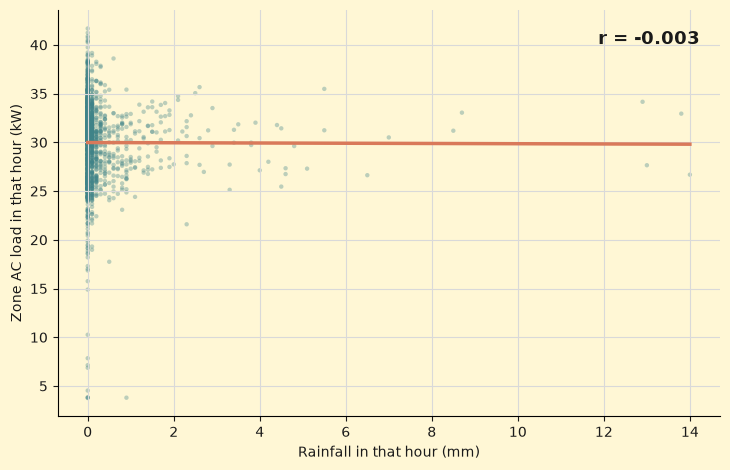

In [ ]:
# Slide chart: AC load vs hourly rainfall (colours match the slide deck)
CREAM, TEAL, ORANGE, INK = '#FFF7D5', '#3F8388', '#D9795A', '#1A1A1A'
x, y = slide_hours['rain'], slide_hours['load']
fig, ax = plt.subplots(figsize=(7.4, 4.8), facecolor=CREAM)
ax.set_facecolor(CREAM)
ax.scatter(x, y, s=10, alpha=0.35, color=TEAL, edgecolors='none')
m, c = np.polyfit(x, y, 1)
xs = np.linspace(x.min(), x.max(), 50)
ax.plot(xs, m * xs + c, color=ORANGE, lw=2.5)
ax.set_xlabel('Rainfall in that hour (mm)', color=INK)
ax.set_ylabel('Zone AC load in that hour (kW)', color=INK)
ax.text(0.97, 0.95, f'r = {x.corr(y):.3f}', transform=ax.transAxes, ha='right', va='top', color=INK, fontsize=13, fontweight='bold')
ax.tick_params(colors=INK)
ax.grid(color='0.85')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig('slide_rainfall.png', dpi=200, facecolor=CREAM)
plt.show()

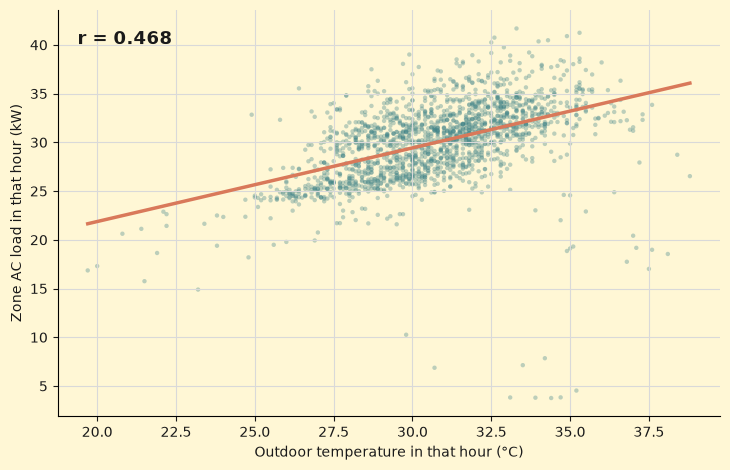

In [ ]:
# Slide chart: AC load vs hourly outdoor temperature
x, y = slide_hours['temp'], slide_hours['load']
fig, ax = plt.subplots(figsize=(7.4, 4.8), facecolor=CREAM)
ax.set_facecolor(CREAM)
ax.scatter(x, y, s=10, alpha=0.35, color=TEAL, edgecolors='none')
m, c = np.polyfit(x, y, 1)
xs = np.linspace(x.min(), x.max(), 50)
ax.plot(xs, m * xs + c, color=ORANGE, lw=2.5)
ax.set_xlabel('Outdoor temperature in that hour (°C)', color=INK)
ax.set_ylabel('Zone AC load in that hour (kW)', color=INK)
ax.text(0.03, 0.95, f'r = {x.corr(y):.3f}', transform=ax.transAxes, ha='left', va='top', color=INK, fontsize=13, fontweight='bold')
ax.tick_params(colors=INK)
ax.grid(color='0.85')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig('slide_temperature.png', dpi=200, facecolor=CREAM)
plt.show()

# Further analysis

Extra checks that support the EDA in `eda_ac_forecasting.ipynb`.

**Data:** `cleaned_data.parquet`, produced by `data_cleaning.ipynb`.

In [ ]:
all_data = pd.read_parquet('../cleaned_data/question_b_hourly_data.parquet')
ac_cols = [c for c in all_data.columns if '_AC' in c]
all_data.shape

## 1. Availability by zone: AC load and indoor temperature

The model needs AC load and indoor temperature for the same zone and hour; indoor humidity is also shown, as a candidate feature (outdoor weather is complete for every hour). An hour counts as available if at least 54 of its 60 minutes have a reading; for AC load, from every working unit in the zone. Floors 2–7 only (Floor 1 has no indoor sensors). Floor 5 zone 1's temperature sensor reads AC supply air, so treat that zone with care.

In [ ]:
# % of hours each month with AC load, indoor temperature, indoor humidity, and both AC load + temperature, for each zone
avail_rows = []
zone_hours = {}
for floor, g in all_data[all_data['Floor'] != 1].set_index('Date').groupby('Floor'):
    for zone in [1, 2, 4, 5]:
        ac = [c for c in ac_cols
              if c.startswith(f'z{zone}_AC') and g[c].notna().any() and g[c].std() > 0]
        if not ac:
            continue
        hours = pd.DataFrame({
            'AC load': g[ac].notna().all(axis=1).resample('h').sum() >= 54,
            'Indoor temp': g[f'z{zone}_S1(degC)'].notna().resample('h').sum() >= 54,
            'Indoor RH': g[f'z{zone}_S1(RH%)'].notna().resample('h').sum() >= 54,
        })
        hours['Both'] = hours['AC load'] & hours['Indoor temp']
        zone_hours[f'Floor {floor} zone {zone}'] = hours
        monthly = hours.groupby(hours.index.to_period('M')).mean().mul(100)
        monthly['Zone'] = f'Floor {floor} zone {zone}'
        avail_rows.append(monthly)

availability = pd.concat(avail_rows).rename_axis('Month').reset_index()

# months with no rows at all (Floor 6 after 22 Oct 2019) count as 0% available
both_monthly = (availability.pivot(index='Zone', columns='Month', values='Both')
                .fillna(0).round(0))
both_monthly

In [ ]:
fig, ax = plt.subplots(figsize=(12, 7))
im = ax.imshow(both_monthly.values, cmap='Blues', vmin=0, vmax=100, aspect='auto')
ax.set_xticks(range(both_monthly.shape[1]), both_monthly.columns.strftime('%b\n%Y'), fontsize=8)
ax.set_yticks(range(both_monthly.shape[0]), both_monthly.index, fontsize=8)
for i in range(both_monthly.shape[0]):
    for j in range(both_monthly.shape[1]):
        value = both_monthly.iat[i, j]
        ax.text(j, i, f'{value:.0f}', ha='center', va='center', fontsize=7,
                color='white' if value > 60 else '0.2')
fig.colorbar(im, ax=ax, label='% of hours with both AC load and indoor temperature')
ax.set_title('Hours with both AC load and indoor temperature, by zone and month')
plt.tight_layout()
plt.show()

In [ ]:
# Summary for the modelling period (March-December 2019): % of all hours available per zone.
# Hours with no data at all (Floor 6 after 22 Oct 2019) count as not available.
full_period = pd.date_range('2019-03-01', '2019-12-31 23:00', freq='h')
modelling_period = pd.DataFrame({
    zone: hours.reindex(full_period, fill_value=False).mean().mul(100)
    for zone, hours in zone_hours.items()
}).T.round(1).sort_values('Both')
modelling_period = modelling_period[['AC load', 'Indoor temp', 'Indoor RH', 'Both']]
modelling_period